# ANALYSE-11 : Synthese transverse des pilotes de digestion

**Serie** : SymbolicAI / Lean -- sous-serie ANALYSE (formalisations digerees)
**Contexte** : critere 6 de l'Epic #13106 (« Digestion et canonicalisation des mathematiques assistees par IA ») -- *une synthese transverse relie les pilotes sans proclamer la canonicalisation achevee sur la seule base d'un build vert*
**Source doctrinale** : Terence Tao, *Mathematics in the Age of AI*, ICM 2026, arXiv:2608.16753 ; Leiden Declaration on AI and Mathematics (2 juin 2026, DOI 10.5281/zenodo.20302944)
**Prerequis** : avoir lu au moins un carnet-pilote (ANALYSE-01, ANALYSE-03 ou Lean-13b) ; Python, pandas, matplotlib, networkx
**Duree estimee** : 35 min

## Navigation

| Notebook precedent | Notebook suivant |
|---|---|
| [ANALYSE-10 - Reflexion Thurston](ANALYSE-10-Reflexion-Thurston-Python.ipynb) | [ANALYSE-12 - Compter les couplages parfaits](ANALYSE-12-Comptage-Matching-Lean-Python.ipynb) |

***

## Presentation

Tao distingue cinq operations que l'acceleration technique tend a confondre : **generer** une preuve, la **verifier**, l'**exposer**, la **publier**, puis la **digerer** et la **canonicaliser**. Les quatre premieres laissent des traces mesurables (un build vert, un `#print axioms`, une prepublication). La cinquieme -- integrer un resultat a un corpus coherent, attribue, comprehensible et enseignable -- est la plus lente et la moins automatisable.

Le depot a mene plusieurs **pilotes** de digestion, chacun sur une famille differente : les baselines d'analyse (Sendov, *Analysis I*, PFR), un pilote quantique (CHSH, Tsirelson, Landau), un pilote narratif (le programme Erdos), un pilote calculatoire borne (minima parasites de Burer-Monteiro), et deux lacs digeres a posteriori (`knot_lean`, `grothendieck_lean`). Chaque pilote a ete ecrit seul, pour sa famille.

Ce carnet les **relie**. Il ne refait aucune digestion ; il pose la meme grille de dix points sur tous les pilotes et mesure ce qui en ressort **en colonne** -- ce qu'aucun pilote, lu isolement, ne peut montrer.

**Ce que ce carnet n'est pas** : un catalogue (le catalogue genere liste les carnets, il ne les confronte pas) ; et surtout pas une declaration de canonicalisation. La section 6 dit explicitement ce que les mesures ne permettent pas de conclure.

## 1. La grille et la methode

La grille de l'Epic #13106 demande a chaque digestion dix documents :

| # | Point de grille |
|---|---|
| 1 | enonce exact et niveau de garantie |
| 2 | provenance, litterature, priorite, attribution |
| 3 | nouveaute reelle par rapport aux dependances |
| 4 | carte des dependances, toolchain, axiomes, hypotheses nommees |
| 5 | portions triviales condensees, portions nouvelles developpees |
| 6 | friction naturelle : obstacles, pivots, essais rates, dette residuelle |
| 7 | chemin de decouverte, distingue de la reconstruction finale |
| 8 | limites, claims non etablis, reserves de review |
| 9 | raccord au corpus CoursIA et prerequis |
| 10 | transmission (exemple, visualisation, exercice) **et revue humaine nommee** |

**Methode.** Chaque case de la matrice pilote x point porte un verdict (`PRESENT`, `PARTIAL`, `ABSENT`) et, sauf `ABSENT`, une **ancre** : une phrase exacte du fichier-pilote qui justifie le verdict. Le verdict est un jugement de lecture ; l'ancre est sa preuve, et elle est **re-verifiee a chaque execution** contre le fichier sur disque. Une ancre qui disparait (le carnet a ete reecrit) degrade la case en `STALE` -- la synthese ne peut pas mentir silencieusement sur un pilote qui a change.

Le point 10 est lu strictement : des « questions pour la revue humaine » valent `PARTIAL` ; seul un relecteur **nomme** ayant relu vaut `PRESENT`.

In [1]:
# Code 1.1 -- Les pilotes, leurs fichiers, et l'etat d'execution des carnets
#
# Le carnet s'execute depuis son dossier (ANALYSE/) ; la racine du depot est 4 niveaux au-dessus.

import json
import os
import pathlib

NB_DIR = pathlib.Path(os.getcwd())
ROOT = NB_DIR.parents[3]
NBS = ROOT / 'MyIA.AI.Notebooks'
assert (ROOT / '.git').exists(), f"racine du depot introuvable depuis {NB_DIR}"

# Table declaree : (pilote, point, verdict, fichier relatif a la racine du depot, ancre)
EVIDENCE = [
[
"BASE-Sendov",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"donne exactement `[propext, Classical.choice, Quot.sound]`"
],
[
"BASE-Sendov",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"**Auteur de la preuve** : Lech Mazur, 2026"
],
[
"BASE-Sendov",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"une formalisation Lean qui **n'est pas de notre cru**"
],
[
"BASE-Sendov",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"ces 20 imports Mathlib (cartographie verbatim c.8266-L1)"
],
[
"BASE-Sendov",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"Le cas interieur est de loin le plus technique"
],
[
"BASE-Sendov",
6,
"ABSENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
""
],
[
"BASE-Sendov",
7,
"ABSENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
""
],
[
"BASE-Sendov",
8,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"Le verdict est donc **SOTA-OK pour le théorème ciblé**"
],
[
"BASE-Sendov",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"## 4. References croisees dans notre serie"
],
[
"BASE-Sendov",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb",
"Trois exercices pour approfondir la comprehension"
],
[
"BASE-Tao",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"donne exactement `[propext, sorryAx, Classical.choice, Quot.sound]`"
],
[
"BASE-Tao",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"**Auteur source** : Terence Tao, depuis 2023"
],
[
"BASE-Tao",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"premier grain de notre serie qui est *Lean-meta*"
],
[
"BASE-Tao",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"n'a que **25 imports Mathlib distincts**"
],
[
"BASE-Tao",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"Choix selectif parmi les lemmes du lac : 5 lemmes"
],
[
"BASE-Tao",
6,
"ABSENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
""
],
[
"BASE-Tao",
7,
"ABSENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
""
],
[
"BASE-Tao",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"il interdit de présenter ce théorème ciblé comme certifié"
],
[
"BASE-Tao",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"## 5. References croisees dans notre serie"
],
[
"BASE-Tao",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb",
"Trois exercices pour approfondir la comprehension du lac"
],
[
"PFR",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"### Le périmètre exact de la garantie"
],
[
"PFR",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"## Provenance, priorité et nouveauté réelle"
],
[
"PFR",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"tient dans un seul mot du titre : **polynomiale**"
],
[
"PFR",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"Deux dépendances tierces : `AddCombi` (combinatoire additive)"
],
[
"PFR",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"Le cas difficile est celui des fibres **équilibrées**"
],
[
"PFR",
6,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"## 8. Friction et chemin de decouverte"
],
[
"PFR",
7,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-04-PFR-Primitives-Python.ipynb",
"ce qui distingue une digestion d'une reconstruction"
],
[
"PFR",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"### 8.3 Dette residuelle - ce qui reste ouvert apres la preuve KAW"
],
[
"PFR",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"## 7. Pont vers la série ICT — l'entropie comme monnaie commune"
],
[
"PFR",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb",
"Trois exercices pour s'approprier les briques"
],
[
"QUANT",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"prouvé localement** (ce lake) | la frontière classique déterministe"
],
[
"QUANT",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"Provenance : J. F. Clauser, M. A. Horne, A. Shimony, R. A. Holt"
],
[
"QUANT",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"importé avec preuve noyau** | la borne quantique elle-même"
],
[
"QUANT",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13c-CHSH-Landau-Saturation.ipynb",
"Ce notebook s'exécute sur le kernel Lean 4 (`lean4-wsl`)"
],
[
"QUANT",
5,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"un exercice d'école, pas une digestion"
],
[
"QUANT",
6,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"Kernel de ce notebook — une divergence assumée, et mesurée"
],
[
"QUANT",
7,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"un kernel dans cet état ne lève pas d'erreur d'import"
],
[
"QUANT",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"## 7. Ce que cette tranche n'établit pas"
],
[
"QUANT",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13d-CHSH-Indeterminisme-Native.ipynb",
"**Prérequis** : le score CHSH et la frontière classique"
],
[
"QUANT",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb",
"Trois exercices bornés pour manipuler les objets du lake"
],
[
"ERDOS",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"toute suite d'au moins `2n − 1` entiers contient une sous-suite"
],
[
"ERDOS",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"## 4. Provenance, attribution et carte des dépendances"
],
[
"ERDOS",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"**Aucune nouveauté mathématique** dans ce notebook"
],
[
"ERDOS",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"kernel `lean4-wsl-groth16200` (pattern per-lake)"
],
[
"ERDOS",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"consommé sans rejeu de preuve"
],
[
"ERDOS",
6,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"## 5. Friction et chemin de découverte"
],
[
"ERDOS",
7,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"Première sonde du smoke, premier réflexe à enseigner"
],
[
"ERDOS",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"## Conclusion — limites et transmission"
],
[
"ERDOS",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"Raccord corpus | [Lean-7b](Lean-07b-Examples-Python.ipynb)"
],
[
"ERDOS",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb",
"Trois exercices exécutables, deux `#print axioms` à lire soi-même"
],
[
"CALC",
1,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"tout minimum local de (BM$_r$) est globalement optimal"
],
[
"CALC",
2,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"Barvinok (1995) – Pataki (1998)"
],
[
"CALC",
3,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"le théorème dit où regarder, le recensement mesure si le réel obéit"
],
[
"CALC",
4,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"le théorème exige la **non-dégénérescence** — condition non vérifiée ici"
],
[
"CALC",
5,
"PARTIAL",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"l'énumération exhaustive des coupes"
],
[
"CALC",
6,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"## D. Friction et essais ratés (chemin de découverte)"
],
[
"CALC",
7,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"c'est cette contradiction qui a révélé le bug"
],
[
"CALC",
8,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"## E. Limites et réserves"
],
[
"CALC",
9,
"PRESENT",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"## Raccord au corpus"
],
[
"CALC",
10,
"PARTIAL",
"MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb",
"Les exercices s'exécutent de bout en bout"
],
[
"KNOT",
1,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"### Prouvés (axiomes `[propext, Quot.sound]` seulement, pas `sorryAx`)"
],
[
"KNOT",
2,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"les priorités mathématiques appartiennent à Fox, Reidemeister, Piccirillo"
],
[
"KNOT",
3,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"## Place dans l'écosystème — nouveauté réelle (digestion #13106, point 3)"
],
[
"KNOT",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"## Dépendances externes"
],
[
"KNOT",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"### Ce qui est acquis"
],
[
"KNOT",
6,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"Historique (certifié, par contre-exemples prouvés)"
],
[
"KNOT",
7,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"### Leçons méthodologiques — chemin de découverte vs reconstruction"
],
[
"KNOT",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"### Scaffolding (sorry, cible formelle)"
],
[
"KNOT",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"## Raccord au corpus et transmission (digestion #13106, points 9-10)"
],
[
"KNOT",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md",
"aucune revue humaine nommée du lake entier"
],
[
"GROTH",
1,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"garantie « 0 `sorry`, 0 axiome ajouté »"
],
[
"GROTH",
2,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"- **Mac Lane, S.; Moerdijk, I.** *Sheaves in Geometry and Logic"
],
[
"GROTH",
3,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"frontière indexée par la Partie 4 (`#check`)"
],
[
"GROTH",
4,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"**Toolchain** : `leanprover/lean4:v4.33.0`"
],
[
"GROTH",
5,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"la trajectoire (sites→faisceaux→cohomologie) hiérarchise"
],
[
"GROTH",
6,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"### Point 6 — friction naturelle (comblement)"
],
[
"GROTH",
7,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"c'est une **visite indexée**, et ce fait est la découverte centrale"
],
[
"GROTH",
8,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"## Le périmètre, honnêtement"
],
[
"GROTH",
9,
"PRESENT",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"navlinks `Lean-15-Grothendieck-Tribute.ipynb`"
],
[
"GROTH",
10,
"PARTIAL",
"MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean/README.md",
"Trois parcours sont proposés selon ton but"
]
]

pilotes = sorted({r[0] for r in EVIDENCE})
fichiers = sorted({r[3] for r in EVIDENCE if r[3]})

def etat_carnet(chemin):
    if chemin.suffix != '.ipynb':
        return 'markdown', None, None
    nb = json.loads(chemin.read_text(encoding='utf-8'))
    code_cells = [c for c in nb['cells'] if c['cell_type'] == 'code']
    executees = sum(1 for c in code_cells if c.get('execution_count') is not None)
    erreurs = sum(1 for c in code_cells for o in c.get('outputs', []) if o.get('output_type') == 'error')
    return 'carnet', f"{executees}/{len(code_cells)}", erreurs

print(f"{len(pilotes)} pilotes, {len(fichiers)} fichiers-pilotes, {len(EVIDENCE)} cases declarees\n")
print(f"{'fichier':<72} {'type':<9} {'exec':>7} {'err':>4}")
for f in fichiers:
    p = ROOT / f
    if not p.exists():
        print(f"{f:<72} MANQUANT")
        continue
    t, ex, er = etat_carnet(p)
    print(f"{f:<72} {t:<9} {ex or '-':>7} {'-' if er is None else er:>4}")

8 pilotes, 11 fichiers-pilotes, 80 cases declarees

fichier                                                                  type         exec  err
MyIA.AI.Notebooks/Search/Part1-Foundations/Search-09b-SpuriousMinima.ipynb carnet        7/7    0
MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-01-Sendov-Lean-Python.ipynb carnet      10/10    0
MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-02-Tao-Lean-Python.ipynb carnet        9/9    0
MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-03-PFR-Lean.ipynb      carnet        9/9    0
MyIA.AI.Notebooks/SymbolicAI/Lean/ANALYSE/ANALYSE-04-PFR-Primitives-Python.ipynb carnet      10/10    0
MyIA.AI.Notebooks/SymbolicAI/Lean/KNOTS/knot_lean/README.md              markdown        -    -
MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-08b-Erdos-Formal-Conjectures-Lean.ipynb carnet      11/11    0
MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13b-CHSH-Tsirelson-Native.ipynb   carnet        8/8    0
MyIA.AI.Notebooks/SymbolicAI/Lean/Lean-13c-CHSH-Landau-Satura

### Lecture du resultat

La table ci-dessus est l'inventaire physique : chaque fichier-pilote existe sur `main`, et pour les carnets on lit combien de cellules de code portent une execution et combien de sorties sont des erreurs. C'est le niveau « verifie » de Tao -- la condition minimale. Un pilote dont le carnet ne s'executerait pas serait disqualifie avant meme la grille ; la suite ne mesure que ce qui a passe ce premier filtre.

## 2. La matrice pilote x grille

On re-verifie chaque ancre contre son fichier, puis on range les verdicts effectifs en matrice : `PRESENT` vaut 1, `PARTIAL` 0,5, `ABSENT` et `STALE` 0.

In [2]:
# Code 2.1 -- Re-verification des ancres et construction de la matrice pilote x point

import pandas as pd

_cache = {}
def texte(rel):
    if rel not in _cache:
        p = ROOT / rel
        if not p.exists():
            _cache[rel] = None
        elif p.suffix == '.ipynb':
            nb = json.loads(p.read_text(encoding='utf-8'))
            _cache[rel] = '\n'.join(''.join(c['source']) for c in nb['cells'])
        else:
            _cache[rel] = p.read_text(encoding='utf-8')
    return _cache[rel]

lignes = []
for pilote, point, verdict, rel, ancre in EVIDENCE:
    effectif = verdict
    if verdict != 'ABSENT':
        t = texte(rel)
        if t is None or ancre not in t:
            effectif = 'STALE'
    lignes.append({'pilote': pilote, 'point': point, 'declare': verdict, 'verifie': effectif})

df = pd.DataFrame(lignes)
SCORE = {'PRESENT': 1.0, 'PARTIAL': 0.5, 'ABSENT': 0.0, 'STALE': 0.0}
df['score'] = df['verifie'].map(SCORE)
mat = df.pivot_table(index='pilote', columns='point', values='score', aggfunc='max').reindex(columns=range(1, 11))

stale = df[df['verifie'] == 'STALE']
print(f"Ancres re-verifiees : {(df['declare'] != 'ABSENT').sum()} ; perimees (STALE) : {len(stale)}")
if len(stale):
    print(stale[['pilote', 'point']].to_string(index=False))
print()
print(df.pivot_table(index='pilote', columns='point', values='verifie', aggfunc='first')
        .reindex(columns=range(1, 11)).fillna('?').to_string())

Ancres re-verifiees : 76 ; perimees (STALE) : 0

point             1        2        3        4        5        6        7        8        9        10
pilote                                                                                               
BASE-Sendov  PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL   ABSENT   ABSENT  PARTIAL  PRESENT  PARTIAL
BASE-Tao     PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL   ABSENT   ABSENT  PRESENT  PRESENT  PARTIAL
CALC         PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL  PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL
ERDOS        PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL  PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL
GROTH        PARTIAL  PARTIAL  PARTIAL  PRESENT  PARTIAL  PARTIAL  PARTIAL  PRESENT  PRESENT  PARTIAL
KNOT         PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL  PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL
PFR          PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL  PRESENT  PRESENT  PRESENT  PRESENT  PARTIAL
QUANT        PRESENT  PRESENT  PR

### Lecture du resultat

Chaque ancre declaree a ete cherchee mot pour mot dans son fichier ; le compte `STALE` dit combien de verdicts ne tiennent plus sur `main`. La matrice verbale qui suit est la synthese brute : une ligne par pilote, une colonne par point de grille. Elle se lit en ligne (« ce pilote est-il une digestion complete ? ») mais elle a ete construite pour etre lue **en colonne** -- c'est l'objet des deux cellules suivantes.

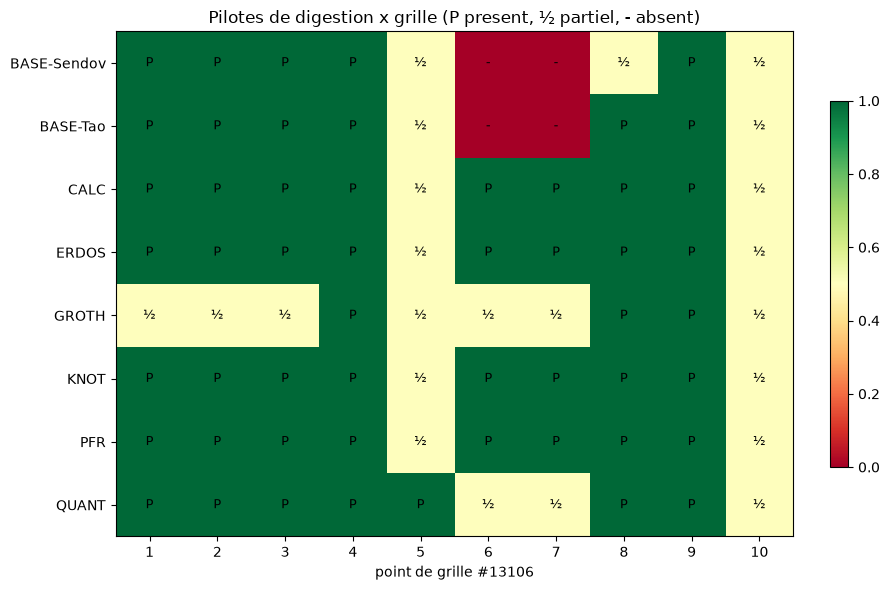

In [3]:
# Code 2.2 -- Carte de chaleur de la matrice

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 0.55 * len(mat) + 1.6))
im = ax.imshow(mat.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(10), [str(i) for i in range(1, 11)])
ax.set_yticks(range(len(mat)), mat.index)
ax.set_xlabel('point de grille #13106')
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, '' if np.isnan(v) else {1.0: 'P', 0.5: '½', 0.0: '-'}[v], ha='center', va='center', fontsize=9)
ax.set_title('Pilotes de digestion x grille (P present, ½ partiel, - absent)')
fig.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()
plt.show()

### Lecture du resultat

Les 76 ancres tiennent sur `main` : aucune case n'est tombee en `STALE`. La carte se lit d'abord par ses **deux bandes verticales jaunes**, pas par ses lignes.

- **Colonne 10 (transmission + revue)** : jaune de haut en bas. Chaque pilote porte un exemple calcule, une figure ou des exercices, mais aucun ne nomme la personne qui l'a relu. Le `PARTIAL` est donc uniforme, et il a la meme cause partout.
- **Colonne 5 (condensation)** : jaune sur sept lignes sur huit. Seul QUANT (Lean-13b/c/d) dit explicitement quelles portions il condense et lesquelles il developpe ; les autres le font sans le declarer.
- **Les deux seuls rouges** sont les points 6 et 7 (friction, chemin de decouverte) des deux baselines Sendov et Tao. Ce n'est pas un defaut de ces carnets : ils precedent la grille, et l'Epic demande de ne pas les modifier sans finding precis. Leur ligne mesure ce que la grille a ajoute a la methode.
- **GROTH** est la seule ligne partielle sur les points 1-3 : le README du lac `grothendieck_lean` decrit ses enonces et sa provenance a grands traits, sans la precision de garantie qu'ont les carnets.

## 3. Lecture en colonne : quels points de la grille la flotte tient-elle ?

Un pilote isole peut omettre un point par choix de sujet. Quand **tous** les pilotes omettent le meme point, ce n'est plus un choix : c'est un angle mort de la methode.

In [4]:
# Code 3.1 -- Lecture en colonne : couverture de chaque point sur l'ensemble des pilotes

couv = mat.mean(axis=0)
partiels = (mat == 0.5).sum(axis=0)
absents = (mat == 0.0).sum(axis=0)
pleins = (mat == 1.0).sum(axis=0)
NOMS = {1: 'enonce/garantie', 2: 'provenance', 3: 'nouveaute', 4: 'dependances', 5: 'condensation',
        6: 'friction', 7: 'chemin de decouverte', 8: 'limites', 9: 'raccord corpus', 10: 'transmission + revue'}
print(f"{'pt':>2} {'point':<22} {'couverture':>10} {'P':>3} {'½':>3} {'-':>3}")
for p in range(1, 11):
    print(f"{p:>2} {NOMS[p]:<22} {couv[p]:>10.2f} {pleins[p]:>3} {partiels[p]:>3} {absents[p]:>3}")
print()
print('Point le mieux tenu  :', NOMS[int(couv.idxmax())], f"({couv.max():.2f})")
print('Point le moins tenu  :', NOMS[int(couv.idxmin())], f"({couv.min():.2f})")
print('Pilotes a revue humaine nommee (point 10 = P) :', list(mat.index[mat[10] == 1.0]) or 'aucun')

pt point                  couverture   P   ½   -
 1 enonce/garantie              0.94   7   1   0
 2 provenance                   0.94   7   1   0
 3 nouveaute                    0.94   7   1   0
 4 dependances                  1.00   8   0   0
 5 condensation                 0.56   1   7   0
 6 friction                     0.62   4   2   2
 7 chemin de decouverte         0.62   4   2   2
 8 limites                      0.94   7   1   0
 9 raccord corpus               1.00   8   0   0
10 transmission + revue         0.50   0   8   0

Point le mieux tenu  : dependances (1.00)
Point le moins tenu  : transmission + revue (0.50)
Pilotes a revue humaine nommee (point 10 = P) : aucun


### Lecture du resultat

La lecture en colonne separe trois groupes de points :

- **tenus par tous** : dependances (4) et raccord au corpus (9), a 1,00 ; enonce, provenance, nouveaute et limites (1-3, 8), a 0,94, la seule perte etant GROTH ou Sendov ;
- **tenus par la moitie** : friction (6) et chemin de decouverte (7), a 0,62 (4 pleins, 2 partiels, 2 absents). Ce sont les points que l'Epic designe comme les premiers effaces par une prose « slick » ; ils sont presents dans les pilotes recents et absents des baselines ;
- **tenus par personne en entier** : condensation (5), a 0,56, et surtout **transmission + revue (10), a 0,50** -- huit partiels, aucun plein.

Le dernier groupe est le resultat le plus net du carnet : **aucun pilote ne porte de revue humaine nommee.** Ce n'est pas une surprise (le README de `knot_lean` le declare lui-meme), mais c'est desormais une mesure sur les huit pilotes, et non un constat sur un seul. Elle correspond exactement au critere 2 de l'Epic, encore ouvert.

## 4. Le certificat ne dit pas la digestion

Tao separe la **verification** de la **digestion**. Le depot dispose d'une mesure de la premiere -- le compte de `sorry` reels d'un lac -- et la matrice fournit une mesure grossiere de la seconde. Les juxtaposer permet de tester l'affirmation centrale de l'Epic : un build vert n'est pas une comprehension.

In [5]:
# Code 4.1 -- Le certificat ne dit pas la digestion : dette formelle des lacs vs couverture de grille
#
# count_code_sorry.py est l'instrument canonique du depot (jamais grep -c sorry) : il distingue
# les sorry reels (code) des mentions en prose. On le confronte a la couverture des pilotes adosses a un lac.

import subprocess, sys

res = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'lean' / 'count_code_sorry.py'), '--json', '--no-vacuous'],
                     capture_output=True, text=True, encoding='utf-8', errors='replace', cwd=ROOT)
lacs = {pathlib.Path(l['lake']).name: l for l in json.loads(res.stdout)['lakes']}

LAC_DE = {'QUANT': 'conway_lean', 'KNOT': 'knot_lean', 'GROTH': 'grothendieck_lean',
          'PFR': 'teorth/pfr', 'BASE-Tao': 'teorth/analysis', 'BASE-Sendov': 'sendov (teorth)', 'ERDOS': 'formal-conjectures'}
print(f"{'pilote':<10} {'lac':<20} {'fichiers':>8} {'sorry reels':>11} {'sorry naifs':>11} {'couverture grille':>18}")
for pilote, lac in LAC_DE.items():
    l = lacs.get(lac)
    if l is None:
        print(f"{pilote:<10} {lac:<20} {'(lac externe, non mesure ici)':>50}")
        continue
    print(f"{pilote:<10} {lac:<20} {l['files']:>8} {l['distinct_code_sorry']:>11} {l['naive_sorry']:>11} {mat.loc[pilote].mean():>18.2f}")

pilote     lac                  fichiers sorry reels sorry naifs  couverture grille
QUANT      conway_lean                87           1         194               0.85
KNOT       knot_lean                  33           8          79               0.90
GROTH      grothendieck_lean         180           0         154               0.65
PFR        teorth/pfr                                (lac externe, non mesure ici)
BASE-Tao   teorth/analysis                           (lac externe, non mesure ici)
BASE-Sendov sendov (teorth)                           (lac externe, non mesure ici)
ERDOS      formal-conjectures                        (lac externe, non mesure ici)


### Lecture du resultat

Trois lacs sont mesurables dans ce depot ; les quatre autres sont externes (`teorth/*`, `formal-conjectures`) et ne sont pas comptes ici. Sur les trois :

- `grothendieck_lean` n'a **aucun** `sorry` reel, et c'est le pilote a la couverture de grille la plus **faible** (0,65) ;
- `knot_lean` en a **8**, et c'est le pilote a la couverture la plus **forte** (0,90) ;
- `conway_lean` en a 1, pour une couverture de 0,85.

Trois points ne font pas une correlation, et la conclusion n'en tire pas une. Ils suffisent en revanche a **refuter l'implication** que l'Epic vise : si « zero `sorry` » entrainait « digere », le lac a zero `sorry` ne pourrait pas etre le moins digere des trois. Le certificat formel et la digestion sont deux mesures independantes.

L'ecart entre `sorry` naifs et reels (154 contre 0 pour `grothendieck_lean`, 194 contre 1 pour `conway_lean`) rappelle au passage pourquoi le compte se fait avec `count_code_sorry.py` : un `grep -c sorry` aurait rendu le lac le plus propre plus « endette » que les deux autres.

## 5. Relier : les pilotes se connaissent-ils ?

Une canonicalisation suppose un corpus **coherent** : un resultat digere doit savoir ou il s'insere parmi les autres. On mesure ici les renvois explicites d'un pilote a un autre (nom de carnet ou de lac cite dans le texte), comptes dans les fichiers-pilotes eux-memes ; une auto-reference ne compte pas.

source       cible        occurrences
BASE-Sendov  BASE-Tao               3
BASE-Tao     BASE-Sendov           35
BASE-Tao     PFR                    2
PFR          BASE-Sendov            2
PFR          BASE-Tao               2

aretes : 5 sur 56 possibles (densite 0.09)
pilotes isoles (ni citant, ni cites) : ['CALC', 'ERDOS', 'GROTH', 'KNOT', 'QUANT']
composantes faiblement connexes : 6 -> [['BASE-Sendov', 'BASE-Tao', 'PFR'], ['CALC'], ['ERDOS'], ['GROTH'], ['KNOT'], ['QUANT']]


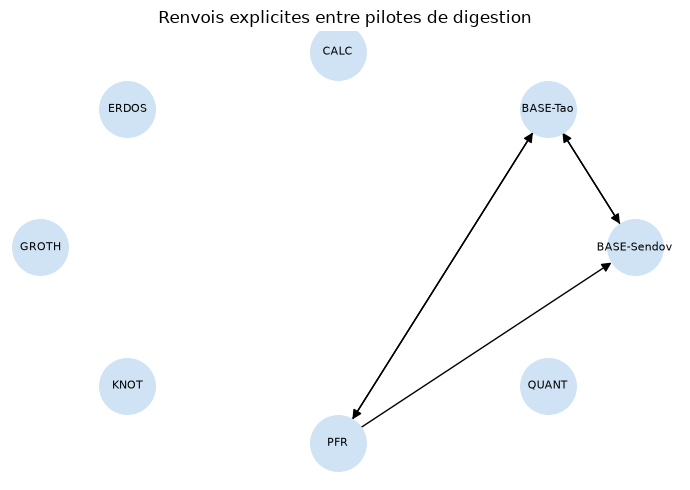

In [6]:
# Code 5.1 -- Les pilotes se citent-ils ? Graphe des renvois entre pilotes
#
# Pour chaque pilote, on cherche dans SES fichiers les motifs qui designent un AUTRE pilote
# (nom de carnet, de lac ou de depot amont). Les auto-references sont exclues.

import re
import networkx as nx

FICHIERS = {}
for pilote, _, _, rel, _ in EVIDENCE:
    FICHIERS.setdefault(pilote, set()).add(rel)
MOTIFS = {
    'BASE-Sendov': r'ANALYSE-01|Sendov', 'BASE-Tao': r'ANALYSE-02|teorth/analysis',
    'PFR': r'ANALYSE-0[34]|teorth/pfr', 'QUANT': r'Lean-13[bcd]|CHSH',
    'ERDOS': r'Lean-08b|formal-conjectures', 'CALC': r'Search-09b|SpuriousMinima',
    'KNOT': r'knot_lean|KNOTS-0', 'GROTH': r'grothendieck_lean|Lean-15-Grothendieck',
}

G = nx.DiGraph()
G.add_nodes_from(pilotes)
print(f"{'source':<12} {'cible':<12} {'occurrences':>11}")
for src_p in pilotes:
    corpus = '\n'.join(texte(r) or '' for r in FICHIERS[src_p])
    for dst_p in pilotes:
        if dst_p == src_p:
            continue
        n = len(re.findall(MOTIFS[dst_p], corpus))
        if n:
            G.add_edge(src_p, dst_p, weight=n)
            print(f"{src_p:<12} {dst_p:<12} {n:>11}")

print(f"\naretes : {G.number_of_edges()} sur {len(pilotes) * (len(pilotes) - 1)} possibles (densite {nx.density(G):.2f})")
isoles = [n for n in G if G.degree(n) == 0]
print('pilotes isoles (ni citant, ni cites) :', isoles or 'aucun')
comp = sorted((sorted(c) for c in nx.weakly_connected_components(G)), key=len, reverse=True)
print(f"composantes faiblement connexes : {len(comp)} ->", comp)

fig, ax = plt.subplots(figsize=(7, 5))
pos = nx.circular_layout(G)
nx.draw_networkx(G, pos, ax=ax, node_color='#cfe3f5', node_size=1600, font_size=8, arrows=True, arrowsize=14)
ax.set_title('Renvois explicites entre pilotes de digestion')
ax.axis('off')
plt.tight_layout()
plt.show()

### Lecture du resultat

Le graphe a **5 aretes sur 56 possibles** (densite 0,09), et toutes relient trois noeuds : Sendov, Tao et PFR, c'est-a-dire la sous-serie ANALYSE elle-meme. L'arete Tao -> Sendov porte a elle seule 35 occurrences : le carnet Tao s'est construit en comparaison explicite avec Sendov.

Les cinq autres pilotes -- CALC, ERDOS, GROTH, KNOT, QUANT -- sont **isoles** : aucun ne cite un autre pilote, et aucun n'est cite. Le graphe compte 6 composantes. Chaque digestion a ete conduite dans sa famille (quantique, combinatoire, optimisation, topologie, geometrie algebrique) avec la grille de #13106 comme seul point commun, mais sans renvoi de l'une a l'autre.

C'est la lacune que le critere 6 de l'Epic designe. Ce carnet est, a la date de son execution, **le premier document du depot qui relie les huit pilotes**. Il ne la comble pas pour autant dans les pilotes eux-memes : un lecteur qui ouvre `knot_lean/README.md` ne sait toujours pas que la meme grille a ete appliquee a CHSH.

## 6. Ce que cette synthese ne conclut pas

Le critere 6 de l'Epic exige de relier les pilotes **sans proclamer la canonicalisation achevee**. Les mesures ci-dessus autorisent trois affirmations et en interdisent trois autres.

**Ce qui est etabli** :
- chaque pilote existe sur `main`, et ses carnets portent leurs executions (section 1) ;
- la matrice pilote x grille est **reproductible** : chaque case non vide est adossee a une phrase verifiee a l'execution (section 2) ;
- la couverture n'est pas uniforme d'un point a l'autre, et le point le moins tenu est nomme (section 3).

**Ce qui n'est pas etabli** :
- **qu'un pilote est canonicalise.** Un `PRESENT` dit qu'une section traite le point, pas qu'elle le traite bien. La qualite d'une digestion se juge par un lecteur, pas par une ancre.
- **qu'un lac a zero `sorry` est digere.** La section 4 montre que la dette formelle et la couverture de grille sont deux grandeurs distinctes ; l'une ne predit pas l'autre.
- **que la revue humaine a eu lieu.** Le point 10 lu strictement est le creux de la matrice ; c'est le critere 2 de l'Epic, encore ouvert. Une synthese ecrite par un agent ne peut pas le combler : elle peut seulement le rendre visible.

La matrice est donc un **instrument de suivi**, pas un certificat : sa valeur tient a ce qu'on la re-execute apres chaque nouvelle digestion, et qu'une ancre perimee y apparaisse en `STALE` au lieu d'y rester verte.

## 7. Exercices

### Exercice 1 -- Ajouter un pilote

Choisissez un carnet de digestion qui n'est pas encore dans la matrice (par exemple `ANALYSE-05-KLS-Lean-Python.ipynb`). Lisez-le, et ajoutez a `EVIDENCE` ses dix lignes (verdict + ancre exacte). Re-executez la section 2 : votre ajout produit-il des `STALE` ? Que dit sa ligne de la matrice ?

In [7]:
# Exercice 1 -- vos dix lignes pour un nouveau pilote
# TODO etudiant : completer NOUVEAU_PILOTE puis l'ajouter a EVIDENCE et re-executer le Code 2.1
NOUVEAU_PILOTE = []  # [('KLS', 1, 'PRESENT', 'SymbolicAI/Lean/ANALYSE/ANALYSE-05-KLS-Lean-Python.ipynb', '<ancre exacte>'), ...]
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 -- Ponderer la grille

Le score moyen traite les dix points comme equivalents. Or l'Epic insiste sur les points 6, 7 et 10 (friction, chemin de decouverte, revue humaine) : ce sont ceux que la prose « slick » efface en premier. Definissez une ponderation qui double ces trois points, recalculez le classement des pilotes, et dites si l'ordre change.

In [8]:
# Exercice 2 -- couverture ponderee
# Indice : poids = pd.Series(1.0, index=range(1, 11)) ; poids[[6, 7, 10]] = 2.0
# TODO etudiant : calculer (mat * poids).sum(axis=1) / poids.sum() et comparer au classement non pondere
classement_pondere = None
print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 -- Detecter la perte d'une ancre

Copiez le texte d'un carnet-pilote dans une variable, retirez-en la phrase qui sert d'ancre a un `PRESENT`, et rejouez la verification du Code 2.1 sur ce texte modifie. Verifiez que la case passe en `STALE`. Pourquoi est-il preferable qu'une case perimee tombe a zero plutot que de garder son ancien verdict ?

In [9]:
# Exercice 3 -- simulation d'une ancre perdue
# Etape 1 : choisir une ligne de EVIDENCE avec verdict PRESENT
# Etape 2 : t = texte(rel).replace(ancre, '')
# TODO etudiant : rejouer le test 'ancre in t' et afficher le verdict effectif
verdict_simule = None
print("Exercice 3 a completer")

Exercice 3 a completer


## 8. Conclusion

Huit pilotes de digestion, conduits dans des familles differentes (analyse, combinatoire additive, quantique, conjectures d'Erdos, optimisation, topologie, geometrie algebrique), ont ete confrontes a la meme grille de dix points. Quatre resultats en sortent, tous re-executables :

1. **La grille est largement tenue** sur l'enonce, la provenance, la nouveaute, les dependances, les limites et le raccord au corpus.
2. **Deux points ne sont tenus en entier par aucun pilote** : la condensation declaree (5), et surtout la revue humaine nommee (10). Le second est le critere 2 de l'Epic ; ce carnet le mesure, il ne le resout pas.
3. **La dette formelle ne predit pas la digestion** : le lac sans `sorry` est le moins digere des trois lacs mesurables.
4. **Les pilotes ne se connaissent pas** : hors de la sous-serie ANALYSE, aucun ne renvoie a un autre.

Dans les termes de Tao, le depot a produit des preuves, les a verifiees et les a exposees. La digestion progresse, pilote par pilote. La **canonicalisation**, qui demande un corpus relie et relu, n'est pas atteinte, et ce carnet ne la declare pas.

Les deux gestes suivants se lisent directement sur les mesures : une relecture humaine nommee sur un premier pilote (elle ferait passer une case de la colonne 10 au vert), et un renvoi croise dans le README de chaque pilote vers les autres (il ajouterait des aretes au graphe). A chaque nouvelle digestion, re-executer ce carnet suffit a voir ce qui a change.